# nmo-synergies: examples

Seven short cases that use the library `nmosyn` directly: the wrong-ordering solution of an experiment, its intercept
$b=\Delta m^2_{31,\rm IO}+\Delta m^2_{31,\rm NO}$, and how it changes with the detector and the unknown parameters.
Intercepts are in $10^{-6}\,\rm eV^2$, splittings in eV².

Cases 1-3 and 7 need no data. Cases 4-6 read the IceCube DeepCore and KM3NeT/ORCA6 releases (`make data`). The
whole notebook runs in about half a minute.

In [1]:
import sys
sys.path.insert(0, '..')    # the repository root, when nmosyn is not installed with pip install -e .

import matplotlib.pyplot as plt
import numpy as np

from nmosyn import fit
from nmosyn.average import bin_solutions, gauss_newton
from nmosyn.experiments.deepcore import DeepCore, edges_one_sigma, window_edges
from nmosyn.experiments.juno import Juno, b_mbr
from nmosyn.experiments.lbl import peaked_beam
from nmosyn.experiments.orca import Orca6
from nmosyn.params import DCP_IO, DCP_NO, S23SQ, X0, b_lbl, b_sbr, intercept
from nmosyn.style import COLORS
from nmosyn.synergy import dchi2_syn

print(f'true splitting X0 = {X0:.4e} eV^2 (NuFIT 6.0, normal ordering)')

true splitting X0 = 2.5340e-03 eV^2 (NuFIT 6.0, normal ordering)


## 1. JUNO: the intercept against the energy resolution

`Juno.scaled(a_res)` builds JUNO with the stochastic term `a_res` of the energy resolution, and the other two terms
scaled with it. `solution(x)` returns the wrong-ordering splitting for normal-ordering Asimov data at the true
splitting `x`, by a Gauss-Newton iteration. A worse resolution averages the solar phase over
higher energies and raises $b$.

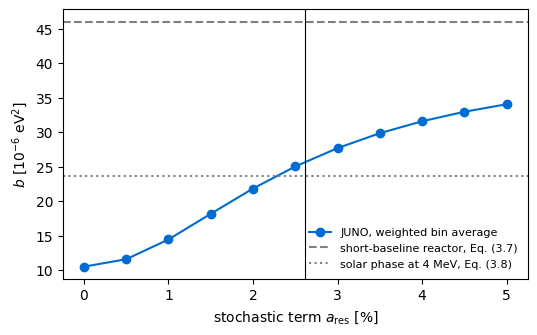

b at a_res = 2.61%: 25.66


In [2]:
a_scan = np.linspace(0.0, 0.05, 11)
b_juno = [intercept(Juno.scaled(a).solution(X0), X0) for a in a_scan]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(100 * a_scan, b_juno, 'o-', color=COLORS['juno'], label='JUNO, weighted bin average')
ax.axhline(b_sbr() * 1e6, color='gray', ls='--', label='short-baseline reactor, Eq. (3.7)')
ax.axhline(b_mbr(4.0) * 1e6, color='gray', ls=':', label='solar phase at 4 MeV, Eq. (3.8)')
ax.axvline(2.61, color='k', lw=0.8)
ax.set(xlabel='stochastic term $a_{\\rm res}$ [%]', ylabel='$b$ [$10^{-6}$ eV$^2$]')
ax.legend(frameon=False, fontsize=8)
plt.show()
print(f'b at a_res = 2.61%: {intercept(Juno().solution(X0), X0):.2f}')

The solution is the average of the values preferred by the single bins, weighted by
$\omega_i = W_i s_i^2$ (Eq. 2.3). `bin_solutions` returns both, and their weighted mean is the solution itself:

In [3]:
juno = Juno()
y = juno.solution(X0)
y_i, omega = bin_solutions(juno._counts, juno._counts(X0), y)
ok = omega > 0
print(f'solution y = {y:.6e}, weighted mean of y_i = {np.average(y_i[ok], weights=omega[ok]):.6e}')

solution y = -2.508338e-03, weighted mean of y_i = -2.508338e-03


## 2. Accelerators: the unknown $\delta_{\rm CP}$

For accelerator $\nu_\mu$ disappearance the solution has a closed form, `b_lbl`, Eq. (3.4). It depends on the true
$\delta_{\rm CP}$ and on the $\delta_{\rm CP}^{\rm IO}$ returned by the fit. In disappearance alone every
$\delta_{\rm CP}^{\rm IO}$ fits nearly equally well, so the solution is a band.

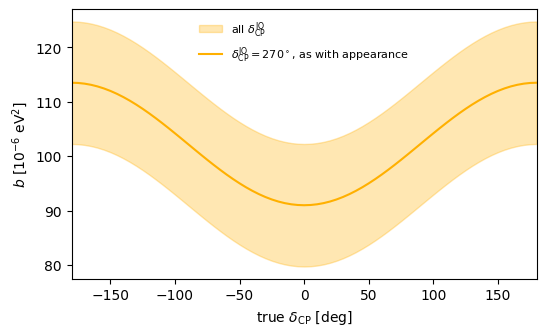

In [4]:
dcp_true = np.radians(np.linspace(-180, 180, 73))
dcp_io = np.radians(np.linspace(-180, 180, 37))
b = np.array([[b_lbl(t, io) * 1e6 for io in dcp_io] for t in dcp_true])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.fill_between(np.degrees(dcp_true), b.min(1), b.max(1), color=COLORS['nova'], alpha=0.3,
                label='all $\\delta_{\\rm CP}^{\\rm IO}$')
ax.plot(np.degrees(dcp_true), [b_lbl(t, np.radians(270)) * 1e6 for t in dcp_true], color=COLORS['nova'],
        label='$\\delta_{\\rm CP}^{\\rm IO} = 270^\\circ$, as with appearance')
ax.set(xlabel='true $\\delta_{\\rm CP}$ [deg]', ylabel='$b$ [$10^{-6}$ eV$^2$]', xlim=(-180, 180))
ax.legend(frameon=False, fontsize=8)
plt.show()

## 3. Your own experiment

The weighted bin average works for any model with a method `counts(y, s23sq, dcp)` that returns the expected
events per bin for the IO splitting `y`, $\sin^2\theta_{23}$, and $\delta_{\rm CP}$. The normal-ordering Asimov data
are `counts(x, ...)` at the true splitting, and `gauss_newton` finds the IO splitting that fits them best. Here
$\theta_{23}$ and both phases are fixed at their NuFIT values.

As an example, `peaked_beam` builds an accelerator with a Gaussian flux at a chosen baseline, peak energy, width,
and antineutrino share, with matter at the density of the crust. Three beams, with neutrinos only and with equal
neutrino and antineutrino runs, against the closed form of Eq. (3.4), which has no matter:

In [5]:
def b_fixed(model, x=X0):
    """Intercept with theta23 and both phases fixed at their NuFIT values."""
    data = model.counts(x, S23SQ, DCP_NO)
    y = gauss_newton(lambda v: model.counts(v, S23SQ, DCP_IO), data, -x + b_lbl(DCP_NO, DCP_IO))
    return intercept(y, x)

beams = {'T2K-like, 295 km, 0.6 GeV': (295, 0.6, 0.1), 'NOvA-like, 810 km, 2 GeV': (810, 2.0, 0.3),
         'DUNE-like, 1300 km, 2.5 GeV': (1300, 2.5, 0.8)}
print(f'closed form, Eq. (3.4): b = {b_lbl(DCP_NO, DCP_IO) * 1e6:.1f}')
print(f'{"":30s}{"neutrinos only":>16s}{"equal shares":>14s}')
for name, (l_km, e_peak, width) in beams.items():
    b_nu, b_eq = (b_fixed(peaked_beam(l_km, e_peak, width, nubar_share=share)) for share in (0.0, 0.5))
    print(f'{name:30s}{b_nu:16.1f}{b_eq:14.1f}')

closed form, Eq. (3.4): b = 110.6
                                neutrinos only  equal shares
T2K-like, 295 km, 0.6 GeV                111.0         110.5
NOvA-like, 810 km, 2 GeV                 106.4         110.5
DUNE-like, 1300 km, 2.5 GeV              115.0         110.6


With equal shares the matter effects of neutrinos and antineutrinos cancel, and every beam returns the closed
form. With neutrinos alone matter moves the solution, in a direction and by an amount that depend on the
baseline and the energy.

## 4. IceCube DeepCore: matter and the detector response

`DeepCore('numu')` is $\nu_\mu$ disappearance with the tabulated response of the public release, `DeepCore('all')`
every channel with appearance. `density_scale=0` switches matter off: in vacuum DeepCore returns nearly the
accelerator closed form, and Earth matter raises $b$ by $\delta_{\rm atm}$.

In [6]:
numu = DeepCore('numu')
b_matter, b_vacuum = b_fixed(numu), b_fixed(DeepCore('numu', density_scale=0.0))
print(f'DeepCore nu_mu in Earth matter: b = {b_matter:.1f}')
print(f'DeepCore nu_mu in vacuum:       b = {b_vacuum:.1f}   (closed form {b_lbl(DCP_NO, DCP_IO) * 1e6:.1f})')
print(f'matter shift delta_atm = {b_matter - b_vacuum:.1f}')

DeepCore nu_mu in Earth matter: b = 119.7
DeepCore nu_mu in vacuum:       b = 110.2   (closed form 110.6)
matter shift delta_atm = 9.5


`gaussian()` replaces the tabulated response with Gaussian kernels, of width `sigma_lne` in $\ln E$ and with
the energy window of `window_edges`:

DeepCore nu_mu, tabulated response: b = 119.7


DeepCore nu_mu, Gaussian kernels of the release: b = 123.0


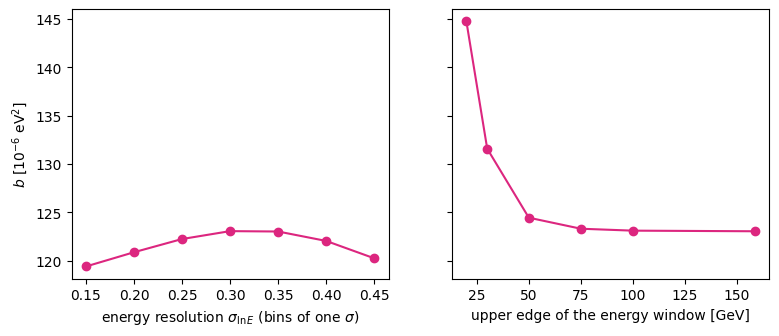

In [7]:
print(f'DeepCore nu_mu, tabulated response: b = {b_fixed(numu):.1f}')
print(f'DeepCore nu_mu, Gaussian kernels of the release: b = {b_fixed(numu.gaussian()):.1f}')

sigmas = np.linspace(0.15, 0.45, 7)
b_sigma = [b_fixed(numu.gaussian(edges_one_sigma(s), sigma_lne=s)) for s in sigmas]
e_max = np.array([20, 30, 50, 75, 100, 158.5])
b_emax = [b_fixed(numu.gaussian(window_edges(e_max=e))) for e in e_max]

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
left.plot(sigmas, b_sigma, 'o-', color=COLORS['dc_numu'])
left.set(xlabel='energy resolution $\\sigma_{\\ln E}$ (bins of one $\\sigma$)', ylabel='$b$ [$10^{-6}$ eV$^2$]')
right.plot(e_max, b_emax, 'o-', color=COLORS['dc_numu'])
right.set(xlabel='upper edge of the energy window [GeV]')
plt.show()

## 5. Two atmospheric detectors: DeepCore and ORCA6

The same calculation for KM3NeT/ORCA6, with all event classes or the high-purity tracks alone (`classes=(1,)`).
Showers carry little weight but pull $b$ down. Here $\theta_{23}$ and the phases are fixed; case 6 frees them.

In [8]:
models = {'DeepCore nu_mu': numu, 'DeepCore all channels': DeepCore('all'),
          'ORCA6 high-purity tracks': Orca6(classes=(1,)), 'ORCA6 all classes': Orca6()}
b_atm = {name: b_fixed(model) for name, model in models.items()}
for name, value in b_atm.items():
    print(f'{name:26s} b = {value:6.1f}')

DeepCore nu_mu             b =  119.7
DeepCore all channels      b =  116.9
ORCA6 high-purity tracks   b =  118.7
ORCA6 all classes          b =  110.7


## 6. Free $\theta_{23}$ and $\delta_{\rm CP}$: the global minimum

In the IO fit $\theta_{23}$ and $\delta_{\rm CP}^{\rm IO}$ are free. At fixed splitting every expected count is a
trigonometric polynomial of degree two in $2\theta_{23}$ and in $\delta_{\rm CP}$, a sum of 25 harmonics, so 25
evaluations fix it exactly. `fit.Harmonics` stores these coefficients on a grid of splittings and gives the counts
at any point, and `fit.global_fit` finds the global minimum over the splitting, $\theta_{23}$ in both octants, and $\delta_{\rm CP}^{\rm IO}$. When
$\delta_{\rm CP}^{\rm IO}$ is poorly constrained, `b_range()` gives the range of equally good solutions.

In [9]:
for name in ('DeepCore nu_mu', 'DeepCore all channels'):
    model = models[name]
    sol = fit.global_fit(fit.Harmonics(model), X0, model.counts(X0, S23SQ, DCP_NO), b_range=(70, 190))
    lo, hi = sol.b_range()
    print(f'{name:22s} fixed: b = {b_atm[name]:5.1f}   free: b = {sol.b:5.1f} (range {lo:.1f}-{hi:.1f}), '
          f'sin^2 theta23 = {sol.s23sq:.3f}, delta_CP^IO = {np.degrees(sol.dcp) % 360:.0f} deg')

DeepCore nu_mu         fixed: b = 119.7   free: b = 131.3 (range 131.3-131.4), sin^2 theta23 = 0.546, delta_CP^IO = 180 deg


DeepCore all channels  fixed: b = 116.9   free: b = 117.8 (range 117.8-118.8), sin^2 theta23 = 0.562, delta_CP^IO = 193 deg


## 7. Synergy of two experiments

Two experiments with different intercepts disagree in the inverted ordering. Their synergy term, Eq. (1.1), is
$(b_A-b_B)^2/(\sigma_A^2+\sigma_B^2)$, with $\sigma$ the precision of each on $|\Delta m^2_{31}|$. For JUNO and
DeepCore (all channels), with the intercepts computed above:

In [10]:
b_a, b_b = intercept(Juno().solution(X0), X0), b_atm['DeepCore all channels']
pcts = [0.5, 1.0, 1.5, 2.0]
print('Delta chi^2_syn   rows: JUNO precision, columns: DeepCore precision [% of |Dm31|]')
print('         ' + ''.join(f'{p:8.1f}' for p in pcts))
for pa in pcts:
    row = [dchi2_syn(b_a, b_b, pa / 100 * X0 * 1e6, pb / 100 * X0 * 1e6) for pb in pcts]
    print(f'{pa:8.1f} ' + ''.join(f'{v:8.1f}' for v in row))

Delta chi^2_syn   rows: JUNO precision, columns: DeepCore precision [% of |Dm31|]
              0.5     1.0     1.5     2.0
     0.5     25.9    10.4     5.2     3.0
     1.0     10.4     6.5     4.0     2.6
     1.5      5.2     4.0     2.9     2.1
     2.0      3.0     2.6     2.1     1.6
